# PowerControlLab · an engineering walkthrough

**400 V DC → 230 Vrms / 50 Hz**

Compare sampled-data control of a lossy LC-filtered H-bridge. Every value below is computed
from the model. The averaged model excludes carrier ripple; the optional switching mode
resolves PWM edges. This notebook assumes the package has been installed with
`python -m pip install -e ".[notebook]"` from the repository root.

The project is a digital-twin foundation; no physical inverter has been calibrated or validated.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from powercontrollab import PlantConfig, SimulationConfig, simulate
from powercontrollab.analysis import compute_metrics
from powercontrollab.analysis.harmonics import harmonic_metrics
from powercontrollab.analysis.metrics import analysis_slice
from powercontrollab.controllers import CONTROLLERS, LABELS
from powercontrollab.reporting import COLORS, STYLE

plant = PlantConfig()
config = SimulationConfig(seed=7)
plt.rcParams.update(STYLE)

## 1 · A common nominal experiment

All controllers start from zero state, share a smooth 20 ms reference ramp, see the same
measurements and use a 20 kHz controller clock. The final five coherent cycles determine
steady RMSE and THD₂–₄₀. A low harmonic distortion does not imply low tracking error.


In [2]:
nominal = {name: simulate(name, plant, config) for name in CONTROLLERS}
rows = [compute_metrics(result) for result in nominal.values()]
table = "| Controller | THD [%] | RMSE [V] | Output [Vrms] |\n|---|---:|---:|---:|\n"
for row in rows:
    table += (
        f"| {LABELS[row['controller']]} | {row['thd_percent']:.4f} | "
        f"{row['steady_rmse_v']:.4f} | {row['output_rms_v']:.3f} |\n"
    )
display(Markdown(table))

| Controller | THD [%] | RMSE [V] | Output [Vrms] |
|---|---:|---:|---:|
| Cascaded PI | 0.0000 | 0.8720 | 230.742 |
| SMC | 0.0000 | 0.0470 | 230.001 |
| Adaptive SMC | 0.0000 | 0.0470 | 230.001 |
| MPC | 0.0000 | 0.0183 | 229.999 |


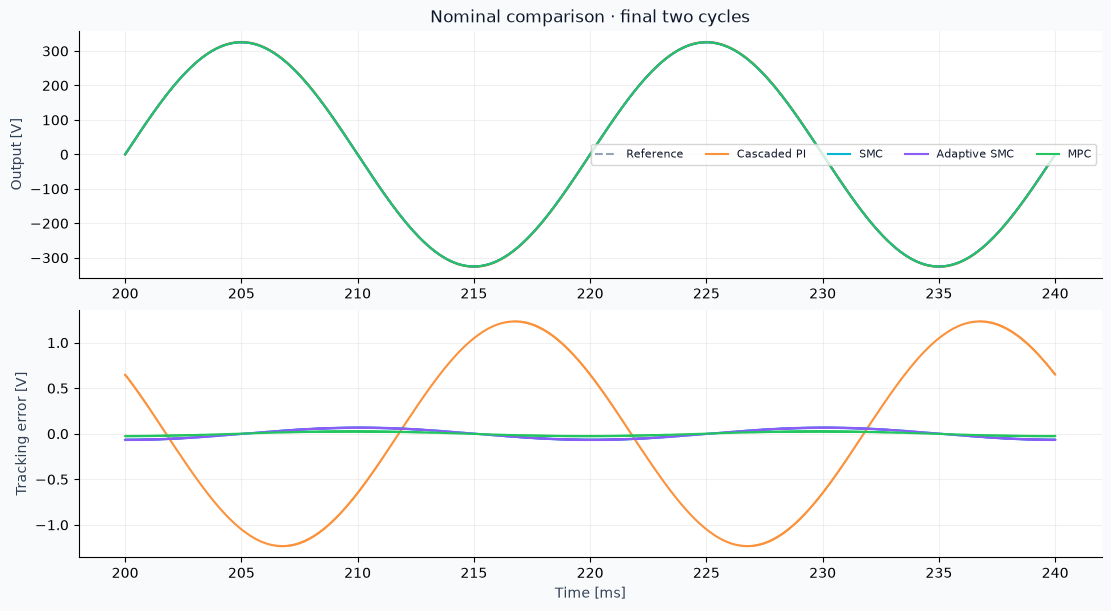

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
first = next(iter(nominal.values()))
select = first.time >= 0.2
axes[0].plot(
    first.time[select] * 1000, first.reference[select], "--", color="#94a3b8", label="Reference"
)
for name, result in nominal.items():
    axes[0].plot(
        result.time[select] * 1000, result.voltage[select], color=COLORS[name], label=LABELS[name]
    )
    axes[1].plot(
        result.time[select] * 1000, (result.reference - result.voltage)[select], color=COLORS[name]
    )
axes[0].set(ylabel="Output [V]", title="Nominal comparison · final two cycles")
axes[0].legend(ncol=5, fontsize=8)
axes[1].set(xlabel="Time [ms]", ylabel="Tracking error [V]")
display(fig)
plt.close(fig)

## 2 · Disturbance recovery

The load resistance drops from 50 Ω to 25 Ω at 100 ms. Recovery is defined using a trailing
one-cycle RMS tracking-error band of 2% of requested RMS voltage. `None` means the criterion
was not confirmed within the finite run; it is not replaced with a fabricated time.


{'steady_rmse_v': 1.1163246281066157, 'settling_time_s': 0.020000000000000004, 'peak_inductor_current_a': 13.166407303478918}


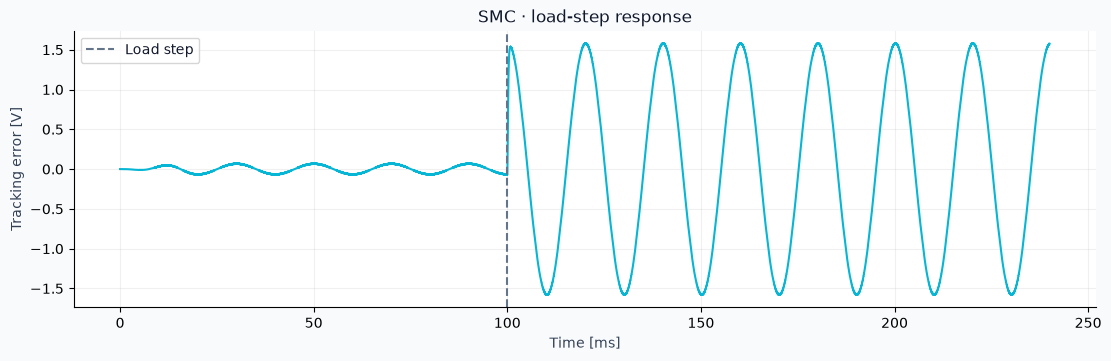

In [4]:
disturbed = simulate("smc", plant, SimulationConfig(scenario="load-step", seed=7))
metrics = compute_metrics(disturbed)
print(
    {key: metrics[key] for key in ("steady_rmse_v", "settling_time_s", "peak_inductor_current_a")}
)
fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.plot(disturbed.time * 1000, disturbed.reference - disturbed.voltage, color=COLORS["smc"])
ax.axvline(100, color="#64748b", linestyle="--", label="Load step")
ax.set(xlabel="Time [ms]", ylabel="Tracking error [V]", title="SMC · load-step response")
ax.legend()
display(fig)
plt.close(fig)

## 3 · Dynamic rectifier load and harmonics

The nonlinear load is a diode bridge charging a DC capacitor and resistor, connected in
parallel with the AC resistance. It adds a physical state and pulsed current demand.
The harmonic spectrum below omits the fundamental so distortion is visible.


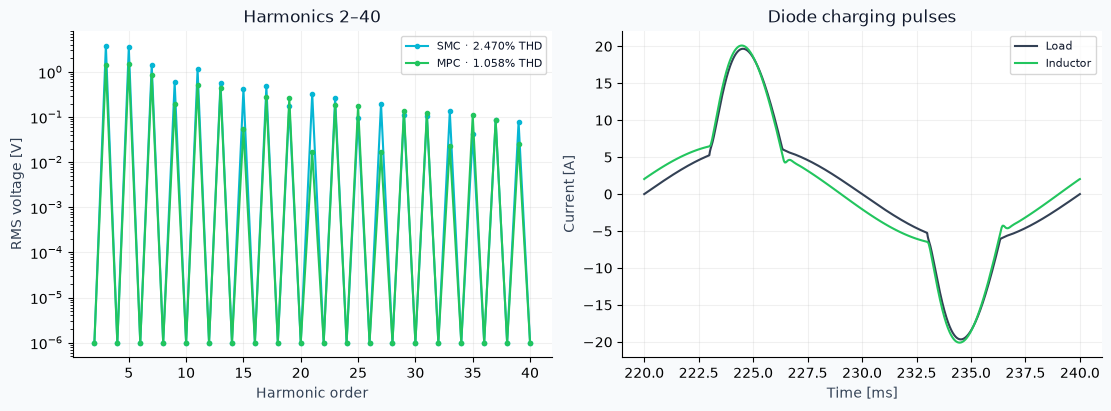

In [5]:
nonlinear = {
    name: simulate(name, plant, SimulationConfig(scenario="nonlinear")) for name in ("smc", "mpc")
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for name, result in nonlinear.items():
    h = harmonic_metrics(
        result.voltage[analysis_slice(result)],
        1 / (result.time[1] - result.time[0]),
        plant.frequency,
    )
    axes[0].semilogy(
        np.arange(2, 41),
        np.maximum(h["harmonic_rms_v"][1:], 1e-6),
        ".-",
        color=COLORS[name],
        label=f"{LABELS[name]} · {h['thd_percent']:.3f}% THD",
    )
result = nonlinear["mpc"]
select = result.time >= 0.22
axes[1].plot(result.time[select] * 1000, result.load_current[select], color="#334155", label="Load")
axes[1].plot(
    result.time[select] * 1000, result.current[select], color=COLORS["mpc"], label="Inductor"
)
axes[0].set(xlabel="Harmonic order", ylabel="RMS voltage [V]", title="Harmonics 2–40")
axes[1].set(xlabel="Time [ms]", ylabel="Current [A]", title="Diode charging pulses")
for ax in axes:
    ax.legend(fontsize=8)
display(fig)
plt.close(fig)

## 4 · Keep the evidence with the experiment

Use `save_result(result, "results/my-experiment")` to export waveforms, plots, parameters,
metrics and source/dependency provenance. Run `python scripts/reproduce.py` from the repository
root for the complete matrix, including switching-model cases.

**Next experiments:** vary the noise seed, compare `mode="switching"`, or extend the run
duration when recovery remains unconfirmed. Before changing controller gains, read
`docs/controllers.md`; before comparing results, read `docs/benchmark.md`.
